In [1]:
race_name = 'Governor'

# Template variables

In [2]:
import utils

utils.mk_formatted_timestamp()

'As of Sunday, 1 November 2026 at 10:08 PM Eastern Time'

In [3]:
import pandas as pd
from matplotlib import pyplot as plt
import geopandas

import sos

test_map = False

# Non-metro
regions_nonmetro = pd.read_csv('./regions/regions_nonmetro.csv', index_col='County')
counties = utils.import_county_map()
counties['Region'] = regions_nonmetro['Region']
regions = counties['Region'].unique()
counties['Subregion'] = regions_nonmetro['Subregion']



# Metro
metro_prec_data = geopandas.read_file('./regions/regions_metro.json')
metro_prec_data = metro_prec_data.rename(columns={'index': 'Precinct'})
metro_prec_data = metro_prec_data.sort_index()

metro_counties = metro_prec_data['County'].values.unique()

def sanitize_mpd(x, county: str, year, replace=' '):
    def worker(y):
        return replace.join(y.split(replace)[1:])
    x.loc[(x['County'] == county) & (x['Election'] == year), 'Precinct'] = \
        x.loc[(x['County'] == county) & (x['Election'] == year), 'Precinct'].apply(worker)
    return x

metro_prec_data = sanitize_mpd(metro_prec_data, 'Gwinnett', '2022')
metro_prec_data = sanitize_mpd(metro_prec_data, 'Hall', '2026', '-')

metro_prec_data['Precinct'] = \
    metro_prec_data['Precinct'].apply(lambda x: x.upper())

metro_prec_data = metro_prec_data.set_index(['Election', 'County', 'Precinct'])
metro_prec_data = metro_prec_data.sort_index()


if test_map:
    fix, ax = plt.subplots(1, 2, figsize=(16, 9))

    counties.plot(column='Region', legend=True, ax=ax[0])
    ax[0].set_axis_off()
    ax[0].set_title('Non-Metro Regions')

    metro_prec_data.loc['2026'].dissolve(level='County').plot(column='Region', ax=ax[1], legend=True)
    ax[1].set_axis_off()
    ax[1].set_title('Metro Regions')

    plt.show()

# Current results

Below shows the current tally of votes for each candidate as shown on the [Secretary of State's website](https://results.sos.ga.gov/results/public/Georgia). It may or may not be a good reflection of the final result.

In [4]:
import numpy as np


def import_historical(year, office, metro=False):
    ext = '_metro' if metro else ''
    unit = ['County', 'Precinct'] if metro else ['County']
    data = pd.read_csv(f'./data/{year}_{office}{ext}.csv', index_col=[*unit, 'Vote Method'])
    data = data.map(int)
    return data


# Up needs to be cut


import statewide_meta


current_year = statewide_meta.current_year
race_meta = statewide_meta.race_data[race_name].loc[current_year]

swing_map = {
    race_meta['Previous Rep']: race_meta['Current Rep'],
    race_meta['Previous Dem']: race_meta['Current Dem'],
    race_meta['Previous Lib']: race_meta['Current Lib'],
}

previous_year = race_meta['Previous Election']
prev = import_historical(previous_year, race_name.lower().replace(' ', '_'))
prev_candidates = prev.columns
prev['Precinct'] = prev.index.get_level_values('County')
prev = prev.reset_index().set_index(['County', 'Precinct', 'Vote Method'])
prev = prev[~prev.index.get_level_values('County').isin(metro_counties)]
prev = pd.concat([prev, import_historical(previous_year, race_name.lower().replace(' ', '_'), metro=True)])

curr, candidates = sos.import_current(race_name, by_method=True)
curr = curr.sort_index()

curr[race_meta['Current Dem']] = prev.loc[curr.index.intersection(prev.index)][race_meta['Previous Dem']]
curr[race_meta['Current Dem']] = curr[race_meta['Current Dem']].fillna(0)
curr[race_meta['Current Dem']] += np.random.normal(500, 10, len(curr))
curr[race_meta['Current Rep']] = prev.loc[curr.index.intersection(prev.index)][race_meta['Previous Rep']]
curr[race_meta['Current Rep']] = curr[race_meta['Current Rep']].fillna(0)
curr[race_meta['Current Rep']] += np.random.normal(100, 10, len(curr))
#curr[race_meta['Current Rep']] *= np.abs(np.random.normal(1.3, .1, len(curr)))
curr[candidates] = curr[candidates].fillna(0).astype(int)
curr.loc[curr.index[0], 'Reported?'] = True
#curr.loc['DeKalb', 'Reported?'] = True
#curr.loc['DeKalb', candidates] = 0

statewide_totals = curr[candidates].sum()
statewide_totals = statewide_totals.sort_values(ascending=False)
(pd.DataFrame({'Votes': statewide_totals, 'Share': (statewide_totals / statewide_totals.sum()).fillna(0)}).style
 .format('{:,}', subset='Votes')
 .format('{:.2%}', subset='Share'))

,Votes,Share
Keisha Lance Bottoms (Dem),"4,324,486",63.98%
Rick Jackson (Rep),"2,434,998",36.02%
David C. Byrne,0,0.00%
Jacqueline Angela DaCosta,0,0.00%
Deb Broughton Davis,0,0.00%
Andrew Pacetti,0,0.00%
Justin Laster,0,0.00%
David C Byrne,0,0.00%
Milton J. Lofton,0,0.00%
David Leon Moreland,0,0.00%


# Map


In [5]:
import matplotlib.colors as mcolors

import colors

missing_kwds = {
    'color': 'lightgray',
    'edgecolor': 'red',
    'hatch': '///',
    'label': 'Missing values'
}

prg_cohort = f'Reporting Group ({previous_year}-{current_year})'

def import_metro_data(df: pd.DataFrame, year, field_from, field_to):
    reporting_groups = metro_prec_data.loc[year, str(field_from)]
    reporting_groups = reporting_groups.groupby(
        level=['County', 'Precinct'], sort=False
    ).first()
    reporting_group_map = reporting_groups.to_dict()

    df[str(field_to)] = [
        group if pd.notna(group) else precinct
        for county, precinct in df.index
        for group in [reporting_group_map.get((county, precinct.upper()), 'Ungrouped')]
    ]
    return df

def import_prgs(df: pd.DataFrame, year):
    return import_metro_data(df, year, prg_cohort, 'Reporting Group')

map_aggs = {cand: 'sum' for cand in candidates}
map_aggs['Reported?'] = 'any'
curr_votes = curr.groupby(['County', 'Precinct']).agg(map_aggs)
#curr_votes = curr_votes[curr_votes['Reported?']]
curr_shares = curr_votes[candidates].div(curr_votes[candidates].sum(axis=1), axis=0).fillna(0)

prev_votes = prev[prev_candidates].groupby(['County', 'Precinct']).sum()
prev_votes = import_prgs(prev_votes, '2022')


prev_votes_prg = prev_votes.groupby(['County', 'Reporting Group']).sum()
prev_shares_prg = prev_votes_prg.div(prev_votes_prg.sum(axis=1), axis=0)

# County summations
county_current = curr[candidates].groupby('County').sum()
county_current = county_current.div(county_current.sum(axis=1), axis=0)
county_previous = prev[prev_candidates].groupby('County').sum()
county_previous = county_previous.div(county_previous.sum(axis=1), axis=0).fillna(0)
county_swings = county_current - county_previous.rename(columns=swing_map)

county_current['Winner'] = county_current.idxmax(axis=1)
curr_shares['Winner'] = curr_shares.idxmax(axis=1)
county_current = geopandas.GeoDataFrame(county_current, geometry=counties['geometry'])
county_swings = geopandas.GeoDataFrame(county_swings, geometry=counties['geometry'])
curr_shares_metro = geopandas.GeoDataFrame(curr_shares.loc[metro_counties].rename(str.upper, level='Precinct'), 
                                           geometry=metro_prec_data.loc[str(current_year)]['geometry'])

# Sanity checks for metro joining

def prec_count_sanity_check(df: pd.DataFrame, gis):
    prec_count_res = df.index.get_level_values('County').value_counts()
    prec_count_gis = gis.index.get_level_values('County').value_counts()
    prec_count_sanity = pd.DataFrame({'Results': prec_count_res, 'GIS': prec_count_gis})
    prec_count_sanity['Diff'] = prec_count_sanity['Results'] - prec_count_sanity['GIS']
    return prec_count_sanity

pcsc1 = prec_count_sanity_check(curr_shares.loc[metro_counties], metro_prec_data.loc[str(current_year)])
assert (pcsc1['Diff'].fillna(0) == 0).all()

In [6]:
# Precinct reporting group summations
curr_votes = import_prgs(curr_votes, str(current_year))
prg_shares = curr_votes.loc[metro_counties]
prg_shares_g = geopandas.GeoDataFrame(prg_shares.rename(str.upper, level='Precinct'), 
                                        geometry=curr_shares_metro['geometry'])
prg_shares_g = prg_shares_g.dissolve(by=['County', 'Reporting Group'], aggfunc={cand: 'sum' for cand in candidates})
prg_shares = prg_shares_g[candidates].div(prg_shares_g[candidates].sum(axis=1), axis=0)
prg_swings = prg_shares - prev_shares_prg.loc[metro_counties].rename(columns=swing_map)
prg_swings = geopandas.GeoDataFrame(prg_swings, geometry = prg_shares_g['geometry'])

#prg_swings[prg_swings['geometry'].isna()].loc['Newton']
pcsc2 = prec_count_sanity_check(prg_shares, prev_shares_prg.loc[metro_counties])
#prg_swings[prg_swings.index.get_level_values('Reporting Group') == 'Ungrouped']
#prev_votes.loc['Douglas'][prev_votes.loc['Douglas']['Reporting Group'] == 'Ungrouped']
#assert (pcsc2['Diff'].fillna(0) == 0).all() # TODO: fix Fulton prg

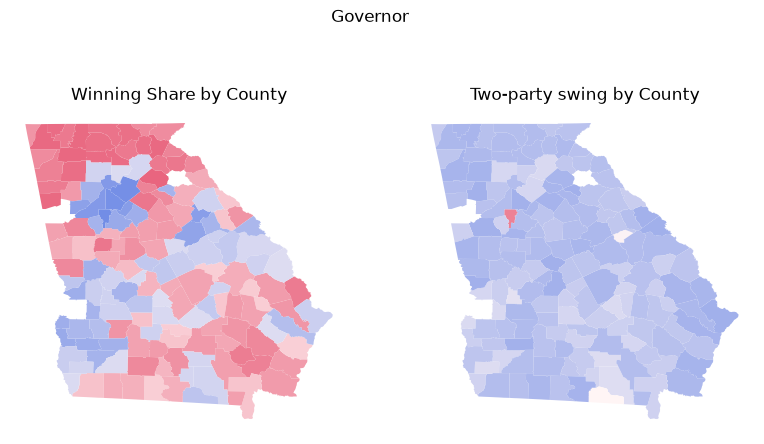

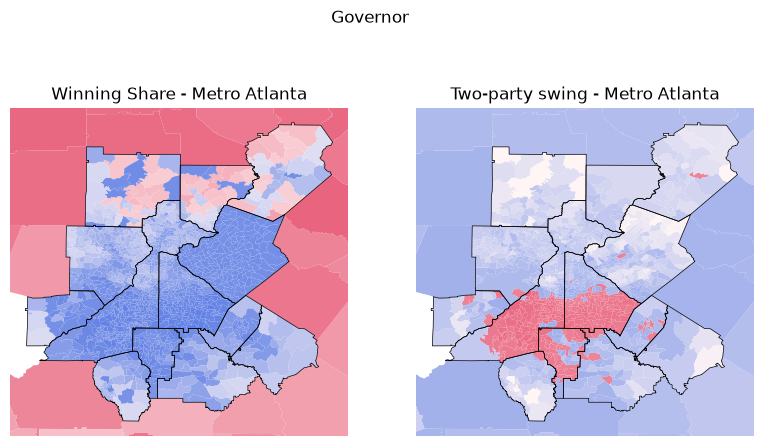

In [7]:
county_swings['TPS'] = (county_swings[race_meta['Current Rep']] - county_swings[race_meta['Current Dem']]) / 2
prg_swings['TPS'] = (prg_swings[race_meta['Current Rep']] - prg_swings[race_meta['Current Dem']]) / 2

fig, [county_share_ax, county_swing_ax] = plt.subplots(1, 2, figsize=utils.INSTAGRAM_LANDSCAPE_RATIO)
fig.suptitle(race_name)
fig, [metro_share_ax, metro_swing_ax] = plt.subplots(1, 2, figsize=utils.INSTAGRAM_LANDSCAPE_RATIO)
fig.suptitle(race_name)

for cmap, cand in zip([colors.republicans, colors.democrats], candidates):
    # County share
    counties_showing = county_current[county_current['Winner'] == cand]
    counties_showing['Metro?'] = counties_showing.index.isin(metro_counties)
    if len(counties_showing) > 0:
        counties_showing.plot(cand, ax=county_share_ax, cmap=cmap, norm=mcolors.Normalize(0.40, 1))

    # Metro share
    prec_showing = curr_shares_metro[curr_shares_metro['Winner'] == cand]
    if len(prec_showing) > 0:
        try:
            prec_showing.plot(cand, ax=metro_share_ax, cmap=cmap, norm=mcolors.Normalize(0.40, 1))

        except ValueError:
            print(prec_showing[prec_showing['geometry'].isna()])
            raise

    nonmetro_counties = counties_showing[~counties_showing['Metro?']]
    if len(nonmetro_counties) > 0:
        nonmetro_counties.plot(cand, ax=metro_share_ax, cmap=cmap, norm=mcolors.Normalize(0.40, 1), autolim=False)

county_share_ax.set_title('Winning Share by County')
county_share_ax.set_axis_off()

metro_share_ax.set_title('Winning Share - Metro Atlanta')
metro_share_ax.set_axis_off()

# TODO: Fix map, sync with other_temp

cnt_swing_halfrange = county_swings['TPS'].abs().max()
cnt_swing_halfrange = np.maximum(cnt_swing_halfrange, 0.1)
swing_norm = mcolors.CenteredNorm(halfrange=cnt_swing_halfrange)
for cmap, sn in zip(['gray', colors.republicans, colors.democrats], [0.0, 1.0, -1.0]):
    counties_showing = county_swings[county_swings['TPS'].map(np.sign) == sn]
    counties_showing['Metro?'] = counties_showing.index.isin(metro_counties)
    
    # County swing
    if len(counties_showing) > 0:
        counties_showing.plot('TPS', ax=county_swing_ax, cmap=cmap, norm=swing_norm)

    # Metro swing
    prg_showing = prg_swings[prg_swings['TPS'].map(np.sign) == sn]
    if len(prg_showing) > 0:
        try:
            prg_showing.plot('TPS', ax=metro_swing_ax, cmap=cmap, norm=swing_norm)

        except ValueError:
            pass

    nonmetro_counties = counties_showing[~counties_showing['Metro?']]
    if len(nonmetro_counties) > 0:
        nonmetro_counties.plot('TPS', ax=metro_swing_ax, cmap=cmap, norm=swing_norm, autolim=False)

linewidth = plt.rcParams['patch.linewidth'] / 2
county_swings.loc[metro_counties].plot(ax=metro_share_ax, color='None', autolim=False, linewidth=linewidth)
county_swings.loc[metro_counties].plot(ax=metro_swing_ax, color='None', autolim=False, linewidth=linewidth)

county_swing_ax.set_title('Two-party swing by County')
county_swing_ax.set_axis_off()

metro_swing_ax.set_title('Two-party swing - Metro Atlanta')
metro_swing_ax.set_axis_off()
plt.show()

# Regional swing model

[Click here to read about my methodology](https://dawieboers.com/2026-midterm-elections/election-night-models/).

* Candidates
    * Share: Projected candidate share based on cell-based uniform swing model. 
    * Swing: One-party swing from previous election.
* Cell-units rep.: Number of cell units in that block that are reporting (completely reporting for Provisionals and at least Election Night Complete for other vote methods).
* Votes counted
    * ENC: Share of the (projected) number of votes that have been counted in reporting units.
    * All: Total number of votes counted divided by projected total number of votes.

In [8]:
curr['Reporting Group'] = curr_votes['Reporting Group']
prev['Reporting Group'] = prev_votes['Reporting Group']

county_idx = curr.index.get_level_values('County')
precinct_idx = curr.index.get_level_values('Precinct').str.upper()
is_metro = county_idx.isin(metro_counties)

# Start with county-level values for non-metro rows.
for field in ('Region', 'Subregion'):
    curr[field] = county_idx.map(counties[field])

# Build a normalized lookup for metro precincts.
metro_lookup = metro_prec_data.loc[str(current_year), ['Region', 'Subregion']].copy()
metro_lookup.index = pd.MultiIndex.from_arrays([
    metro_lookup.index.get_level_values('County'),
    metro_lookup.index.get_level_values('Precinct').str.upper(),
])

metro_keys = pd.MultiIndex.from_arrays([county_idx, precinct_idx])
matched = metro_keys.isin(metro_lookup.index)

for field in ('Region', 'Subregion'):
    values = metro_lookup[field].reindex(metro_keys[is_metro])
    curr.loc[is_metro, field] = values.to_numpy()

    # Preserve the fallback for metro precincts absent from the lookup.
    missing_metro = is_metro & ~matched
    curr.loc[missing_metro, field] = 'Ungrouped'

aggs = {cand: np.sum for cand in candidates}
aggs['Region'] = 'first'
aggs['Subregion'] = 'first'
aggs['Reported?'] = 'all'
curr_by_prg = curr.groupby(['County', 'Reporting Group', 'Vote Method']).agg(aggs)
prev_by_prg = prev.groupby(['County', 'Reporting Group', 'Vote Method']).agg(np.sum)
prev_by_prg.columns = pd.MultiIndex.from_product([['Previous'], prev_by_prg.columns])
curr_by_prg_votes = curr_by_prg[candidates]
curr_by_prg_votes.columns = pd.MultiIndex.from_product([['Current'], candidates])
df_votes = curr_by_prg_votes.join(prev_by_prg)
df_votes[['Region', 'Subregion', 'Reported?']] = curr_by_prg[['Region', 'Subregion', 'Reported?']]
df_votes = df_votes.reset_index().set_index(['Region', 'Vote Method', 'County', 'Reporting Group'])
df_votes = df_votes.sort_index()

# Regional swings
swings = df_votes[df_votes['Reported?']]
swings = swings.groupby(['Region', 'Vote Method']).agg(np.sum)

swings['Vote Growth Ratio'] = (
    (swings['Current'].sum(axis=1) / swings['Previous'].sum(axis=1))
    .replace(np.inf, 0)  # Votes before but no votes now (1 / 0 = infinity), set to 0, resulting in no projected votes. 
    .fillna(1)           # No votes before or now (0 / 0 = nan), set to 1, indicating no change
)

swings['Previous'] = swings['Previous'].div(
    swings['Previous'].sum(axis=1),
    axis=0,
).fillna(0)
swings['Current'] = swings['Current'].div(
    swings['Current'].sum(axis=1),
    axis=0,
).fillna(0)

reverse_swing_map = {curr_cand: prev_cand for prev_cand, curr_cand in swing_map.items()}




# Project results onto unreported areas.
unreported = df_votes[~df_votes['Reported?']]

if len(unreported) > 0:
    unreported['Vote Growth Ratio'] = swings['Vote Growth Ratio']
    unreported['Vote Growth Ratio'] = unreported['Vote Growth Ratio'].fillna(1)
    unreported['Projected Total'] = (unreported['Previous'].sum(axis=1) * unreported['Vote Growth Ratio']).astype(int)
    unreported['Projected Total'] = np.maximum(unreported['Projected Total'], unreported['Current'].sum(axis=1))
    unreported['Projected Total'] = np.maximum(unreported['Projected Total'], 1)  
    # ^^ Prevent provisional cells from being zeroed out giving a misleading interpretation
    #    in the remaining votes projection that provisionals are done being counted.                                 

    unreported['Previous'] = unreported['Previous'].div(
        unreported['Previous'].sum(axis=1),
        axis=0,
    ).fillna(0)

    for cand in swings['Current'].columns:
        # Take the swings in reported areas
        if cand in list(reverse_swing_map.keys()):
            prev_cand = reverse_swing_map[cand]
            regional_baseline = swings[('Previous', prev_cand)]
            county_baseline = unreported[('Previous', prev_cand)]

        else:
            regional_baseline = 0
            county_baseline = 0

        swing = swings[('Current', cand)] - regional_baseline
        swing_c = swing.reindex(unreported.index).fillna(0)
        unreported[('Current', cand)] = county_baseline + swing_c

        unreported[('Swing', cand)] = swing_c
        swings[('Swing', cand)] = swing

    unreported['Current'] = unreported['Current'].clip(0, 1)
    # Should probably ensure it adds to 100 for each unit
    unreported['Current'] = unreported['Current'].mul(
        unreported['Projected Total'],
        axis=0
    ).fillna(0).map(int)

candidates_filter = [race_meta['Current Rep'], race_meta['Current Dem']]

def build_pt_table(index_levels: list[str] = []):
    if len(index_levels) == 0:
        group_df = lambda x: pd.DataFrame([x.sum()], index=['Total'])
        select_df = lambda _: df_votes

    else:
        group_df = lambda x: x.groupby(index_levels).sum()
        select_df = lambda cell: df_votes.xs(cell, level=index_levels[0])

    
    current_pt = group_df(unreported['Current']).add(
        group_df(df_votes[df_votes['Reported?']]['Current']),  # Add actually counted votes
        fill_value = 0
    )
    previous_pt = group_df(df_votes['Previous'])
    pt_index = current_pt.index
    pt_cells = pd.DataFrame(index=pt_index, columns=pd.MultiIndex.from_product([candidates, ['Share', 'Swing']]))

    for cand in candidates:
        pt_cells[cand, 'Share'] = share = current_pt[cand].div(current_pt.sum(axis=1), axis=0) * 100
        #pt_cells[cand, 'MoE'] = swings['stdev'].div(swings['Reported?'].map(np.sqrt), axis=0) * 1.96
        #pt_cells[cand, 'MoE'] = pt_cells[cand, 'MoE'].fillna(0)

        if cand in reverse_swing_map:
            prev_cand = reverse_swing_map[cand]
            prev_share = previous_pt[prev_cand].div(previous_pt.sum(axis=1), axis=0) * 100
            pt_cells[cand, 'Swing'] = share - prev_share

        else:
            pt_cells[cand, 'Swing'] = share

    units_reported = [reported for reported in (
        select_df(cell)['Reported?']
        for cell in pt_index
    )]
    pt_cells['Cell-units rep.'] = [
        f'{reported.sum()} / {reported.size}'
        for reported in units_reported
    ]

    projected_total = current_pt.sum(axis=1)
    pt_cells[[('Votes counted', 'ENC'), ('Votes counted', 'All')]] = [
        (units[units['Reported?']]['Current'].sum().sum(),
        units['Current'].sum().sum()
        )
        for units in (
            select_df(cell)
            for cell in pt_index
        )
    ]
    pt_cells['Votes counted'] = pt_cells['Votes counted'].div(projected_total, axis=0)

    pt_cells = pt_cells[pt_cells[('Votes counted', 'ENC')] > 0]

    return pt_cells

main_table = build_pt_table(['Region', 'Vote Method'])
region_table = build_pt_table(['Region'])
method_table = build_pt_table(['Vote Method'])
total_table = build_pt_table()
disected_pt_table = pd.concat([region_table, method_table, total_table], keys=['Region', 'Method', 'Total'], names=['Crosstable', 'Cell'])



# Determine mode
any_rep_by_cell = df_votes['Reported?'].groupby(['Vote Method', 'Region']).agg(np.any)
if any_rep_by_cell.all():
    is_model_viable = True

else:
    empty_enc_cells = any_rep_by_cell[~any_rep_by_cell].loc[['Absentee by Mail', 'Advance Voting', 'Election Day']]
    is_model_viable = len(empty_enc_cells) == 0
    #is_model_viable = True


show_table = disected_pt_table if is_model_viable else main_table

(show_table[[*candidates_filter, 'Cell-units rep.', 'Votes counted']]
    .style
    .format('{:.2f}', subset=[(cand, 'Share') for cand in candidates_filter])
    .format('{:+.1f}', subset=[(cand, 'Swing') for cand in candidates_filter])
    #.format('±{:.1f}', subset=[(cand, 'MoE') for cand in candidates_filter])
    .format('{:.2%}', subset=['Votes counted'])
    .bar(subset=['Votes counted'], color='green', vmin=0, vmax=1, width=100)
)

## By subregion

Subregions appearing here have at least enough votes counted to adequately calculate a swing.

The swings listed here cut across vote methods, so they won't be skewed by the fact that only some voting methods have been counted, e.g. Early votes which tend to lean Democratic.

In [9]:
prev_votes_statewide = prev[prev_candidates].sum()
prev_share_ru = prev_votes_statewide[race_meta['Previous Runner-up']] / prev_votes_statewide.sum() * 100
swing_req_s = 50.0 - prev_share_ru
challenger_party = colors.party_name(race_meta['Previous Runner-up'])
swing_required = (challenger_party, swing_req_s)

rep_by_cell = df_votes.droplevel('Region')['Reported?']
mask = rep_by_cell['Absentee by Mail'] & rep_by_cell['Election Day'] & rep_by_cell['Advance Voting']
by_unit = df_votes[['Current', 'Previous']].groupby(['County', 'Reporting Group']).sum()
by_unit = by_unit.loc[mask]
by_unit['Region'] = df_votes.reset_index('Region')['Region'].groupby(['County', 'Reporting Group']).first()[by_unit.index]
by_unit['Subregion'] = df_votes['Subregion'].groupby(['County', 'Reporting Group']).first()[by_unit.index]

by_subregion = by_unit.groupby(['Region', 'Subregion']).sum()

if len(by_subregion) > 1:
    by_subregion.loc[('Total', 'Total'), :] = by_subregion.sum(axis=0)

    # Normalize
by_subregion['Current'] = by_subregion['Current'].div(by_subregion['Current'].sum(axis=1), axis=0) * 100
by_subregion['Previous'] = by_subregion['Previous'].div(by_subregion['Previous'].sum(axis=1), axis=0) * 100

margins = by_subregion['Current', race_meta['Current Rep']] - by_subregion['Current', race_meta['Current Dem']]
swings = by_subregion['Current', race_meta['Challenger']] - by_subregion['Previous', reverse_swing_map[race_meta['Challenger']]] 

(pd.DataFrame({'Margin': margins, 'Swing': swings.map(lambda s: (challenger_party, s))}).style
    .format(utils.point_formatter, subset=['Margin', 'Swing'])
    .map(utils.points_format_block, subset=['Margin'])
    .map(utils.points_format_font, subset=['Swing']))

,,Margin,Swing
Region,Subregion,,


## Swingometer

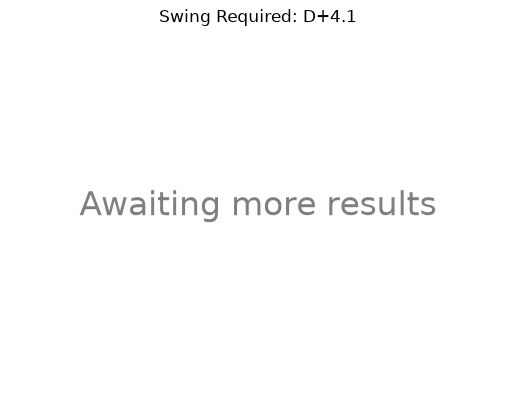

In [10]:
import dials

fig, ax = plt.subplots()

ax.set_title(f'Swing Required: {utils.point_formatter(swing_required)}')
ax.set_axis_off()

if is_model_viable:
    proj_share = total_table.loc['Total'].xs('Share', level=1)[race_meta['Challenger']]
    proj_swing = proj_share - prev_share_ru

    dials.dial_from_swing_required(swing_req_s, proj_swing, ax, pty=challenger_party)
    ax.text(0, -0.2, f'Swing Projected: {utils.point_formatter((challenger_party, proj_share))}', ha='center')
    # TODO: fix interior (margin) labels


elif 'Total' in by_subregion.index:
    measured_swing = swings.loc[('Total', 'Total')]

    dials.dial_from_swing_required(swing_req_s, measured_swing, ax, pty=challenger_party)
    ax.text(0, -0.2, f'Swing Measured: {utils.point_formatter((challenger_party, measured_swing))}', ha='center')


else:
    ax.text(0.5, 0.5, 'Awaiting more results', ha='center', fontsize=24, alpha=0.5)
    
        

# Estimated votes remaining

We use a variable called a Vote Growth Ratio to help us predict the total number of votes cast before they are all counted. The Vote Growth Ratio is calculated in each region, segmented by vote method. It is the ratio between the number of votes counted in completed counties/precincts and the number of votes cast in the previous election. Like the regional swing model, it gets more accurate as the night carries on. 

## By region

In [11]:
projected_remaining = unreported['Projected Total'] - df_votes[~df_votes['Reported?']]['Current'].sum(axis=1)
pvr_by_region = utils.sort_and_share(pd.DataFrame(projected_remaining.groupby(level='Region').sum(), columns=['Votes']))
(pvr_by_region.style
    .format('{:,}', subset=['Votes'])
    .format('{:.2f}%', subset=['Share']))

,Votes,Share
Region,,
Gwinnett,"104,458",63.65%
South,"28,787",17.54%
North Metro Atlanta,"16,278",9.92%
West Metro Atlanta,"10,107",6.16%
South Metro Atlanta,"3,867",2.36%
Fulton,618,0.38%
DeKalb,0,0.00%
East,0,0.00%
Middle,0,0.00%


## By method

In [12]:
pvr_by_method = utils.sort_and_share(pd.DataFrame(projected_remaining.groupby(level='Vote Method').sum(), columns=['Votes']))
(pvr_by_method.style
    .format('{:,}', subset=['Votes'])
    .format('{:.2f}%', subset=['Share']))

,Votes,Share
Vote Method,,
Advance Voting,"106,495",64.89%
Election Day,"28,833",17.57%
Absentee by Mail,"28,787",17.54%
Provisional,0,0.00%


## Summary

This table shows whether the number of remaining votes is enough to change the result. If the number in the bottom row ("Estimated votes remaining") is greater than either of the other two numbers, there is still a possibility of change.

If the number of estimated votes remaining is greater than the number in the first row (Votes required to swap places in count) then it is still possible for the currently-trailing candidate to take the lead. 

If the number of estimated votes remaining is greater than the number in the second row (Votes required to force/avoid runoff) then it is still an open question as to whether or not there will be a runoff. Note that for two-candidate races, these numbers are effectively the same. 

If the margin is within the legal range for a recount, this will be indicated by a message just above the table.

In [13]:
import race_decider

race_decider.remaining_votes_summary(df_votes['Current'].sum(), projected_remaining)

,0
Votes required to swap places in count,"1,889,489"
Votes required to force runoff,"1,889,488"
Estimated votes remaining,"164,115"


## Possible ranges

The table shows the minimum and maximum possible shares of the votes each candidate could receive at this point. The minimum share is if all remaining votes were counted for another candidate, and the maximum share is if all remaining votes were counted for the given candidate. This is an obtuse, but fairly definitive way of determining the final outcome.

If a candidate's minimum vote share is greater than 50%, they must win.

In [14]:
completed_counties = df_votes[df_votes['Reported?']]['Current'].sum()
counted_votes = df_votes['Current'].sum()
proj_total_votes = unreported['Projected Total'].sum() + completed_counties.sum()

if df_votes['Current'].sum().sum() > 0 and 'Total' in total_table.index:
    foo = total_table.loc['Total'].xs('Share', level=1).rename('Projected Share')

else:
    foo = pd.Series(np.zeros(len(candidates)), index=candidates, name='Projected Share')

range_table = pd.DataFrame(foo)
range_table['Min. Share'] = counted_votes / proj_total_votes * 100
range_table['Max. Share'] = (counted_votes + projected_remaining.sum()) / proj_total_votes * 100
range_table.style.format('{:.2f}%')


,Projected Share,Min. Share,Max. Share
Rick Jackson (Rep),45.00%,35.17%,37.54%
Keisha Lance Bottoms (Dem),55.00%,62.46%,64.83%
David C. Byrne,0.00%,0.00%,2.37%
Jacqueline Angela DaCosta,0.00%,0.00%,2.37%
Deb Broughton Davis,0.00%,0.00%,2.37%
Andrew Pacetti,0.00%,0.00%,2.37%
Justin Laster,0.00%,0.00%,2.37%
David C Byrne,0.00%,0.00%,2.37%
Milton J. Lofton,0.00%,0.00%,2.37%
David Leon Moreland,0.00%,0.00%,2.37%


# Timeline

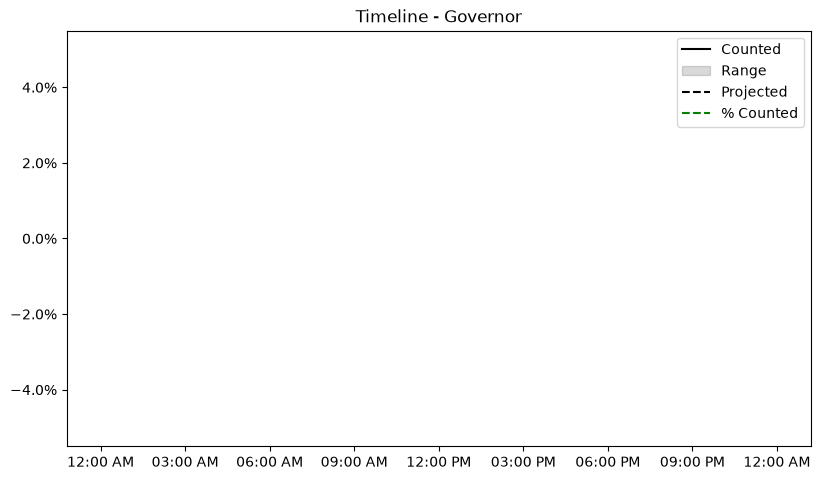

In [15]:
import os

import timelines

timeline_filename = f'./timelines/{race_name.replace(' ', '_')}.csv'

if os.path.exists(timeline_filename):
    timeline = pd.read_csv(timeline_filename, index_col='Timestamp')

else:
    timeline = timelines.build_template_timeline()

total_votes = curr[candidates].sum().sum()
fig, ax = plt.subplots(figsize=utils.INSTAGRAM_LANDSCAPE_RATIO)
ax.set_title(f'Timeline - {race_name}')
if total_votes > 0:
    dem_cand = race_meta['Current Dem']
    rep_cand = race_meta['Current Rep']
    new_entry = {
        'Dem Counted': curr[dem_cand].sum() / total_votes,
        'Dem Min. 1': range_table['Min. Share'][dem_cand] / 100.0,
        'Dem Max. 1': range_table['Max. Share'][dem_cand] / 100.0,
        'Dem Projected': range_table['Projected Share'][dem_cand] / 100.0,
        'Rep Counted': curr[rep_cand].sum() / total_votes,
        'Rep Min. 1': range_table['Min. Share'][rep_cand] / 100.0,
        'Rep Max. 1': range_table['Max. Share'][rep_cand] / 100.0,
        'Rep Projected': range_table['Projected Share'][rep_cand] / 100.0,
        'Projected Progress': total_votes / proj_total_votes
    }

    timelines.display(timeline=timeline, new_entry=new_entry, ax=ax, timeline_filename=timeline_filename)


else:
    timelines.show_awaiting_results(ax)
    
plt.show()
# This works, ignore the fact it looks like it doesn't when testing.